<a href="https://colab.research.google.com/github/fiap-ia-2025/phase06-cardioia/blob/main/Cardio_IA.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 🫀 CardioIA — Sistema Preditivo Multiagente para Eventos Cardíacos

## 1. Introdução e objetivo

O projeto **CardioIA** tem como objetivo desenvolver um sistema preditivo para identificação de situações de pico de risco em um ambiente hospitalar, utilizando técnicas de **Machine Learning** e, posteriormente, uma arquitetura de **agentes inteligentes**.

Nesta primeira etapa, será desenvolvido o componente preditivo do sistema. O modelo receberá dados sintéticos relacionados às condições dos pacientes e ao funcionamento do ambiente hospitalar, estimando a probabilidade de ocorrência de um pico de risco.

A saída do modelo será posteriormente estruturada para integração com a segunda etapa do projeto, na qual agentes especializados poderão utilizar a previsão, consultar protocolos e organizar sugestões de resposta operacional.


# 🩺 Parte 1
## 2. Geração e exploração dos dados

Para desenvolver e testar o modelo preditivo, será utilizada uma base de dados sintética. Os dados representam diferentes características relacionadas ao paciente e ao funcionamento do sistema hospitalar.

A base contém variáveis clínicas e operacionais, como frequência cardíaca, saturação de oxigênio, pressão arterial, carga do sistema, tempo de espera e disponibilidade de recursos.

A variável-alvo `pico_risco` representa a ocorrência ou não de um pico de risco:

- `0`: sem pico de risco;
- `1`: pico de risco.

A geração dos dados utiliza uma semente aleatória fixa para garantir reprodutibilidade dos resultados.

In [46]:
import numpy as np
import pandas as pd
import os
import matplotlib.pyplot as plt
from matplotlib.gridspec import GridSpec
from matplotlib.patches import FancyBboxPatch, Wedge
import joblib
from google.colab import files
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

### 2.1. Geração da base de dados simulada

Para o treinamento do modelo preditivo, será utilizada a base de dados simulada fornecida no enunciado da atividade.

A base contém 5.000 registros com variáveis relacionadas às condições do paciente e ao funcionamento do ambiente hospitalar.

A variável `risk_score` é calculada a partir de seis condições de risco:

- carga do sistema superior a 80%;
- tempo de espera superior a 60 minutos;
- saturação de oxigênio inferior a 92%;
- frequência cardíaca superior a 110 bpm;
- mais de 4 eventos nas últimas 24 horas;
- disponibilidade de recursos inferior a 40%.

Cada condição satisfeita acrescenta um ponto ao `risk_score`. A variável `pico_risco` é definida como `1` quando o `risk_score` é igual ou superior a 2, e como `0` caso contrário.
```

In [47]:
np.random.seed(42)
n = 5000

df = pd.DataFrame({
    "idade_media": np.random.normal(55, 12, n).clip(18, 90),
    "carga_sistema": np.random.uniform(30, 100, n),
    "tempo_espera": np.random.normal(45, 20, n).clip(5, 180),
    "fc_media": np.random.normal(85, 15, n).clip(50, 150),
    "spo2_media": np.random.normal(95, 3, n).clip(70, 100),
    "pa_sistolica": np.random.normal(125, 20, n).clip(80, 200),
    "temperatura": np.random.normal(24, 5, n).clip(10, 40),
    "densidade_eventos": np.random.poisson(3, n),
    "eventos_24h": np.random.poisson(2, n),
    "disponibilidade_recursos": np.random.uniform(20, 100, n)
})

risk_score = (
    (df["carga_sistema"] > 80).astype(int) +
    (df["tempo_espera"] > 60).astype(int) +
    (df["spo2_media"] < 92).astype(int) +
    (df["fc_media"] > 110).astype(int) +
    (df["eventos_24h"] > 4).astype(int) +
    (df["disponibilidade_recursos"] < 40).astype(int)
)

df["pico_risco"] = (risk_score >= 2).astype(int)

### 2.2. Análise inicial dos dados

Após a geração da base, é realizada uma análise inicial para verificar suas dimensões, as variáveis disponíveis, a distribuição da variável-alvo e algumas estatísticas descritivas.

Essa etapa permite verificar se os dados foram gerados corretamente e observar a distribuição das classes antes do treinamento dos modelos.

In [48]:

print("Dimensões da base:", df.shape)

print("\nColunas:")
print(df.columns.tolist())

print("\nDistribuição da variável pico_risco:")
print(df["pico_risco"].value_counts())

print("\nResumo estatístico:")
display(df.describe())


Dimensões da base: (5000, 11)

Colunas:
['idade_media', 'carga_sistema', 'tempo_espera', 'fc_media', 'spo2_media', 'pa_sistolica', 'temperatura', 'densidade_eventos', 'eventos_24h', 'disponibilidade_recursos', 'pico_risco']

Distribuição da variável pico_risco:
pico_risco
0    3671
1    1329
Name: count, dtype: int64

Resumo estatístico:


,idade_media,carga_sistema,tempo_espera,fc_media,spo2_media,pa_sistolica,temperatura,densidade_eventos,eventos_24h,disponibilidade_recursos,pico_risco
count,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.00000,5000.000000,5000.000000
mean,55.058872,64.637825,45.243077,85.305275,94.920231,124.893487,24.003366,2.998000,1.99240,60.271841,0.265800
std,11.925581,19.987923,19.383549,14.897908,2.874954,19.529416,5.080669,1.731876,1.41843,23.030132,0.441802
min,18.000000,30.003698,5.000000,50.000000,83.430874,80.000000,10.000000,0.000000,0.00000,20.035489,0.000000
25%,47.105140,47.604462,31.838260,75.000614,92.900337,111.201401,20.514351,2.000000,1.00000,40.186700,0.000000
50%,55.161587,64.430649,45.143356,85.218044,94.984043,125.058077,23.967477,3.000000,2.00000,60.871675,0.000000
75%,62.992127,81.684947,58.278490,95.604945,97.009198,138.054290,27.506223,4.000000,3.00000,80.393247,1.000000
max,90.000000,99.977124,113.578210,150.000000,100.000000,198.832490,40.000000,13.000000,9.00000,99.989376,1.000000


## 3. Preparação e treinamento dos modelos

Antes do treinamento, os dados são separados em variáveis preditoras (`X`) e variável-alvo (`y`).

As colunas `risk_score` e `pico_risco` não são utilizadas diretamente como entradas do modelo. O `pico_risco` representa o resultado que desejamos prever, enquanto o `risk_score` é utilizado durante a construção da variável-alvo e, portanto, não deve ser fornecido ao modelo como variável de entrada.

Em seguida, a base é dividida em conjuntos de treinamento e teste, mantendo a proporção das classes por meio do parâmetro `stratify`.

In [49]:
# Separar entradas e variável-alvo
X = df.drop(columns=["pico_risco"])
y = df["pico_risco"]

# Dividir em 80% treino e 20% teste
X_treino, X_teste, y_treino, y_teste = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Treino:", X_treino.shape)
print("Teste:", X_teste.shape)
print("\nDistribuição das classes:")
print(y.value_counts())

Treino: (4000, 10)
Teste: (1000, 10)

Distribuição das classes:
pico_risco
0    3671
1    1329
Name: count, dtype: int64


### 3.1. Regressão Logística

Como primeiro modelo preditivo, será utilizada a **Regressão Logística**, um algoritmo de classificação capaz de estimar a probabilidade de pertencimento a uma das classes.

O modelo será treinado utilizando o conjunto de treinamento e posteriormente avaliado sobre dados que não participaram do processo de treinamento.

In [50]:
modelo = LogisticRegression(max_iter=1000)

modelo.fit(X_treino, y_treino)

print("Modelo treinado com sucesso!")


Modelo treinado com sucesso!



## 4. Avaliação do modelo preditivo

Nesta etapa, avaliaremos o desempenho da Regressão Logística
utilizando o conjunto de teste, que não foi utilizado durante
o treinamento.

Serão analisadas as seguintes métricas:
- Acurácia: proporção total de previsões corretas.
- Precisão: proporção de previsões positivas que realmente são positivas.
- Recall: proporção dos casos positivos reais identificados pelo modelo.
- F1-score: equilíbrio entre precisão e recall.
- Matriz de confusão: quantidade de acertos e erros em cada classe.


Acurácia: 0.8160

Relatório de classificação:
                   precision    recall  f1-score   support

Sem pico de risco       0.85      0.91      0.88       734
    Pico de risco       0.69      0.55      0.62       266

         accuracy                           0.82      1000
        macro avg       0.77      0.73      0.75      1000
     weighted avg       0.81      0.82      0.81      1000

Matriz de confusão:
[[669  65]
 [119 147]]


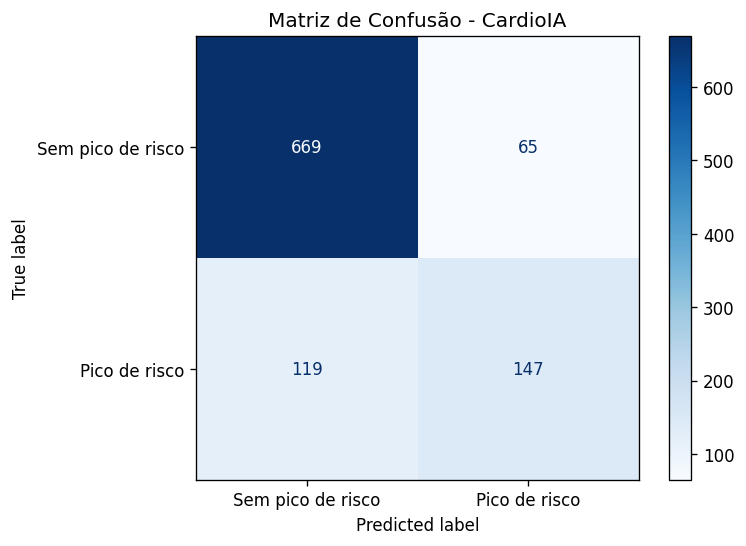

In [51]:
# Realizar previsões no conjunto de teste
y_pred = modelo.predict(X_teste)

# Calcular a acurácia
acuracia = accuracy_score(y_teste, y_pred)
print(f"Acurácia: {acuracia:.4f}")

# Relatório de classificação
print("\nRelatório de classificação:")
print(classification_report(
    y_teste,
    y_pred,
    labels=[0, 1],
    target_names=["Sem pico de risco", "Pico de risco"],
    zero_division=0
))

# Matriz de confusão
matriz = confusion_matrix(y_teste, y_pred, labels=[0, 1])
print("Matriz de confusão:")
print(matriz)

# Visualizar a matriz
disp = ConfusionMatrixDisplay(
    confusion_matrix=matriz,
    display_labels=["Sem pico de risco", "Pico de risco"]
)
disp.plot(cmap="Blues", values_format="d")
plt.title("Matriz de Confusão - CardioIA")
plt.show()



## 5. Simulação de previsão para um novo paciente

Nesta etapa, utilizaremos dados clínicos sintéticos de um novo
paciente para obter a classificação prevista e a probabilidade
estimada pelo modelo treinado.

A previsão é acadêmica e não representa diagnóstico médico.


In [52]:
# Dados simulados do novo paciente
novo_caso = pd.DataFrame([{
    "idade_media": 62,
    "carga_sistema": 92,
    "tempo_espera": 75,
    "fc_media": 118,
    "spo2_media": 89,
    "pa_sistolica": 100,
    "temperatura": 37.5,
    "densidade_eventos": 7,
    "eventos_24h": 5,
    "disponibilidade_recursos": 25
}])

# Garantir a mesma ordem de colunas usada no treinamento
novo_caso = novo_caso[X_treino.columns]

# Obter classificação e probabilidade
classe_prevista = modelo.predict(novo_caso)[0]
probabilidade = modelo.predict_proba(novo_caso)[0, 1]

print(f"Probabilidade estimada de pico de risco: {probabilidade:.2%}")
print(f"Classe prevista: {classe_prevista}")


Probabilidade estimada de pico de risco: 99.88%
Classe prevista: 1



### 5.1. Aplicação dos protocolos simulados

As condições do novo paciente serão comparadas com a base
de protocolos para identificar as ações operacionais aplicáveis.


In [53]:
# Aplicar regras da base simulada ao novo paciente
paciente = novo_caso.iloc[0]
protocolos_sugeridos = []

if paciente["carga_sistema"] > 85:
    protocolos_sugeridos.append(
        "Carga do sistema > 85%: abrir unidades temporárias."
    )

if paciente["spo2_media"] < 88:
    protocolos_sugeridos.append(
        "SpO2 < 88%: iniciar suporte respiratório imediato."
    )

if paciente["disponibilidade_recursos"] < 30:
    protocolos_sugeridos.append(
        "Disponibilidade de recursos < 30%: redistribuir insumos."
    )

print(f"RISCO PREVISTO: {probabilidade:.2%}")
print(f"CLASSIFICAÇÃO: {'Pico de risco' if classe_prevista == 1 else 'Sem pico de risco'}")
print("\nPROTOCOLOS SUGERIDOS:")

for protocolo in protocolos_sugeridos:
    print(f"- {protocolo}")


RISCO PREVISTO: 99.88%
CLASSIFICAÇÃO: Pico de risco

PROTOCOLOS SUGERIDOS:
- Carga do sistema > 85%: abrir unidades temporárias.
- Disponibilidade de recursos < 30%: redistribuir insumos.


## 6. Comparação entre modelos preditivos

Nesta etapa, treinaremos uma Árvore de Decisão para comparar seu desempenho com o da Regressão Logística. Os dois modelos serão avaliados no mesmo conjunto de teste.

Como a classe *Pico de risco* possui menos exemplos, utilizaremos o parâmetro `class_weight="balanced"` para dar maior peso à classe minoritária durante o treinamento. A comparação considerará precisão, recall, F1-score e acurácia.

In [54]:
# Treinar a Árvore de Decisão
modelo_arvore = DecisionTreeClassifier(
    random_state=42,
    class_weight="balanced"
)

modelo_arvore.fit(X_treino, y_treino)

# Realizar previsões
y_pred_arvore = modelo_arvore.predict(X_teste)

# Avaliar o modelo
print("ÁRVORE DE DECISÃO")
print(f"Acurácia: {accuracy_score(y_teste, y_pred_arvore):.4f}")

print("\nRelatório de classificação:")
print(classification_report(
    y_teste,
    y_pred_arvore,
    labels=[0, 1],
    target_names=["Sem pico de risco", "Pico de risco"],
    zero_division=0
))

print("\nMatriz de confusão:")
print(confusion_matrix(y_teste, y_pred_arvore, labels=[0, 1]))


ÁRVORE DE DECISÃO
Acurácia: 0.9960

Relatório de classificação:
                   precision    recall  f1-score   support

Sem pico de risco       1.00      1.00      1.00       734
    Pico de risco       0.99      0.99      0.99       266

         accuracy                           1.00      1000
        macro avg       0.99      0.99      0.99      1000
     weighted avg       1.00      1.00      1.00      1000


Matriz de confusão:
[[732   2]
 [  2 264]]


### 6.1 Visualização da matriz de confusão

A matriz de confusão permite visualizar os acertos e erros do modelo de Árvore de Decisão em cada classe. Ela ajuda a identificar quantos casos de pico de risco foram detectados e quantos passaram despercebidos.

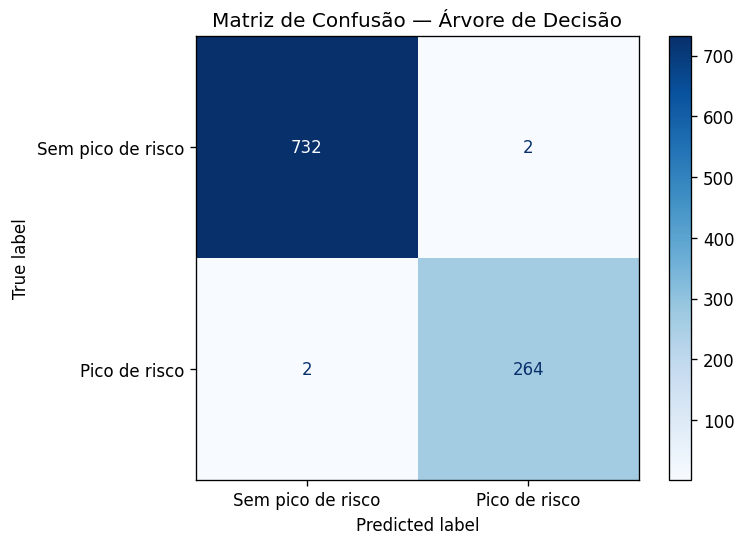

In [55]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay, confusion_matrix

matriz_arvore = confusion_matrix(
    y_teste,
    y_pred_arvore,
    labels=[0, 1]
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=matriz_arvore,
    display_labels=["Sem pico de risco", "Pico de risco"]
)

disp.plot(cmap="Blues", values_format="d")
plt.title("Matriz de Confusão — Árvore de Decisão")
plt.show()

## 7. Simulação de previsão para um novo paciente

Nesta etapa, utilizaremos a Árvore de Decisão treinada para analisar um novo caso simulado. O modelo retornará a probabilidade estimada de pico de risco e sua classificação. Em seguida, regras operacionais serão verificadas para identificar os protocolos aplicáveis.

**Observação:** os dados e protocolos são simulados para fins acadêmicos e não substituem avaliação clínica.

In [56]:
# Dados do novo paciente
novo_caso = pd.DataFrame([{
    "idade_media": 62,
    "carga_sistema": 92,
    "tempo_espera": 75,
    "fc_media": 118,
    "spo2_media": 89,
    "pa_sistolica": 100,
    "temperatura": 37.5,
    "densidade_eventos": 7,
    "eventos_24h": 5,
    "disponibilidade_recursos": 25
}])

# Garantir a mesma ordem de variáveis usada no treinamento
novo_caso = novo_caso[X_treino.columns]

# Prever classe e probabilidade com a Árvore de Decisão
classe_arvore = modelo_arvore.predict(novo_caso)[0]
indice_positivo = list(modelo_arvore.classes_).index(1)
probabilidade_arvore = modelo_arvore.predict_proba(
    novo_caso
)[0, indice_positivo]

# Verificar os protocolos operacionais
paciente = novo_caso.iloc[0]

protocolos = [
    {
        "Protocolo": "Iniciar suporte respiratório imediato",
        "Condição": "SPO2 < 88%",
        "Acionado": paciente["spo2_media"] < 88
    },
    {
        "Protocolo": "Abrir unidades temporárias",
        "Condição": "Carga do sistema > 85%",
        "Acionado": paciente["carga_sistema"] > 85
    },
    {
        "Protocolo": "Iniciar monitoramento intensivo",
        "Condição": "FC > 120",
        "Acionado": paciente["fc_media"] > 120
    },
    {
        "Protocolo": "Ativar equipe de resposta rápida",
        "Condição": "Eventos_24h > 5",
        "Acionado": paciente["eventos_24h"] > 5
    },
    {
        "Protocolo": "Redistribuir insumos",
        "Condição": "Disponibilidade de recursos < 30%",
        "Acionado": paciente["disponibilidade_recursos"] < 30
    },
    {
        "Protocolo": "Priorizar triagem emergencial",
        "Condição": "Tempo de espera > 90 min",
        "Acionado": paciente["tempo_espera"] > 90
    },
    {
        "Protocolo": "Iniciar protocolo infeccioso",
        "Condição": "Temperatura > 38°C média",
        "Acionado": paciente["temperatura"] > 38
    },
    {
        "Protocolo": "Ativar plano de contingência",
        "Condição": "Densidade de eventos > 6",
        "Acionado": paciente["densidade_eventos"] > 6
    },
    {
        "Protocolo": "Iniciar protocolo de choque",
        "Condição": "PA sistólica < 90",
        "Acionado": paciente["pa_sistolica"] < 90
    },
    {
        "Protocolo": "Ativar estado de emergência",
        "Condição": "Risco sistêmico alto",
        "Acionado": classe_arvore == 1
    }
]

print(f"RISCO PREVISTO: {probabilidade_arvore:.2%}")
print(
    "CLASSIFICAÇÃO:",
    "Pico de risco" if classe_arvore == 1 else "Sem pico de risco"
)

print("\nPROTOCOLOS SUGERIDOS:")
for protocolo in protocolos:
    if protocolo["Acionado"]:
        print(f'- {protocolo["Condição"]}: {protocolo["Protocolo"]}.')

RISCO PREVISTO: 100.00%
CLASSIFICAÇÃO: Pico de risco

PROTOCOLOS SUGERIDOS:
- Carga do sistema > 85%: Abrir unidades temporárias.
- Disponibilidade de recursos < 30%: Redistribuir insumos.
- Densidade de eventos > 6: Ativar plano de contingência.
- Risco sistêmico alto: Ativar estado de emergência.


## 8. Verificação de overfitting

Nesta etapa, vamos comparar o desempenho da Árvore de Decisão nos dados de treinamento e nos dados de teste. Uma diferença muito grande entre os resultados pode indicar overfitting.

In [57]:
# Avaliação nos dados de treinamento
y_pred_treino = modelo_arvore.predict(X_treino)
acuracia_treino = accuracy_score(y_treino, y_pred_treino)

# Avaliação nos dados de teste
y_pred_teste = modelo_arvore.predict(X_teste)
acuracia_teste = accuracy_score(y_teste, y_pred_teste)

print(f"Acurácia no treinamento: {acuracia_treino:.4f}")
print(f"Acurácia no teste:       {acuracia_teste:.4f}")
print(f"Diferença:               {acuracia_treino - acuracia_teste:.4f}")

print("\nRelatório de classificação no teste:")
print(classification_report(
    y_teste,
    y_pred_teste,
    target_names=["Sem pico de risco", "Pico de risco"]
))

Acurácia no treinamento: 1.0000
Acurácia no teste:       0.9960
Diferença:               0.0040

Relatório de classificação no teste:
                   precision    recall  f1-score   support

Sem pico de risco       1.00      1.00      1.00       734
    Pico de risco       0.99      0.99      0.99       266

         accuracy                           1.00      1000
        macro avg       0.99      0.99      0.99      1000
     weighted avg       1.00      1.00      1.00      1000



## 9. Painel visual de risco e protocolos

O painel resume a saída do modelo de forma visual. A barra representa a probabilidade estimada de pico de risco, enquanto a tabela apresenta as condições operacionais avaliadas e informa se cada protocolo foi acionado. Essa visualização facilita a interpretação e a apresentação dos resultados.

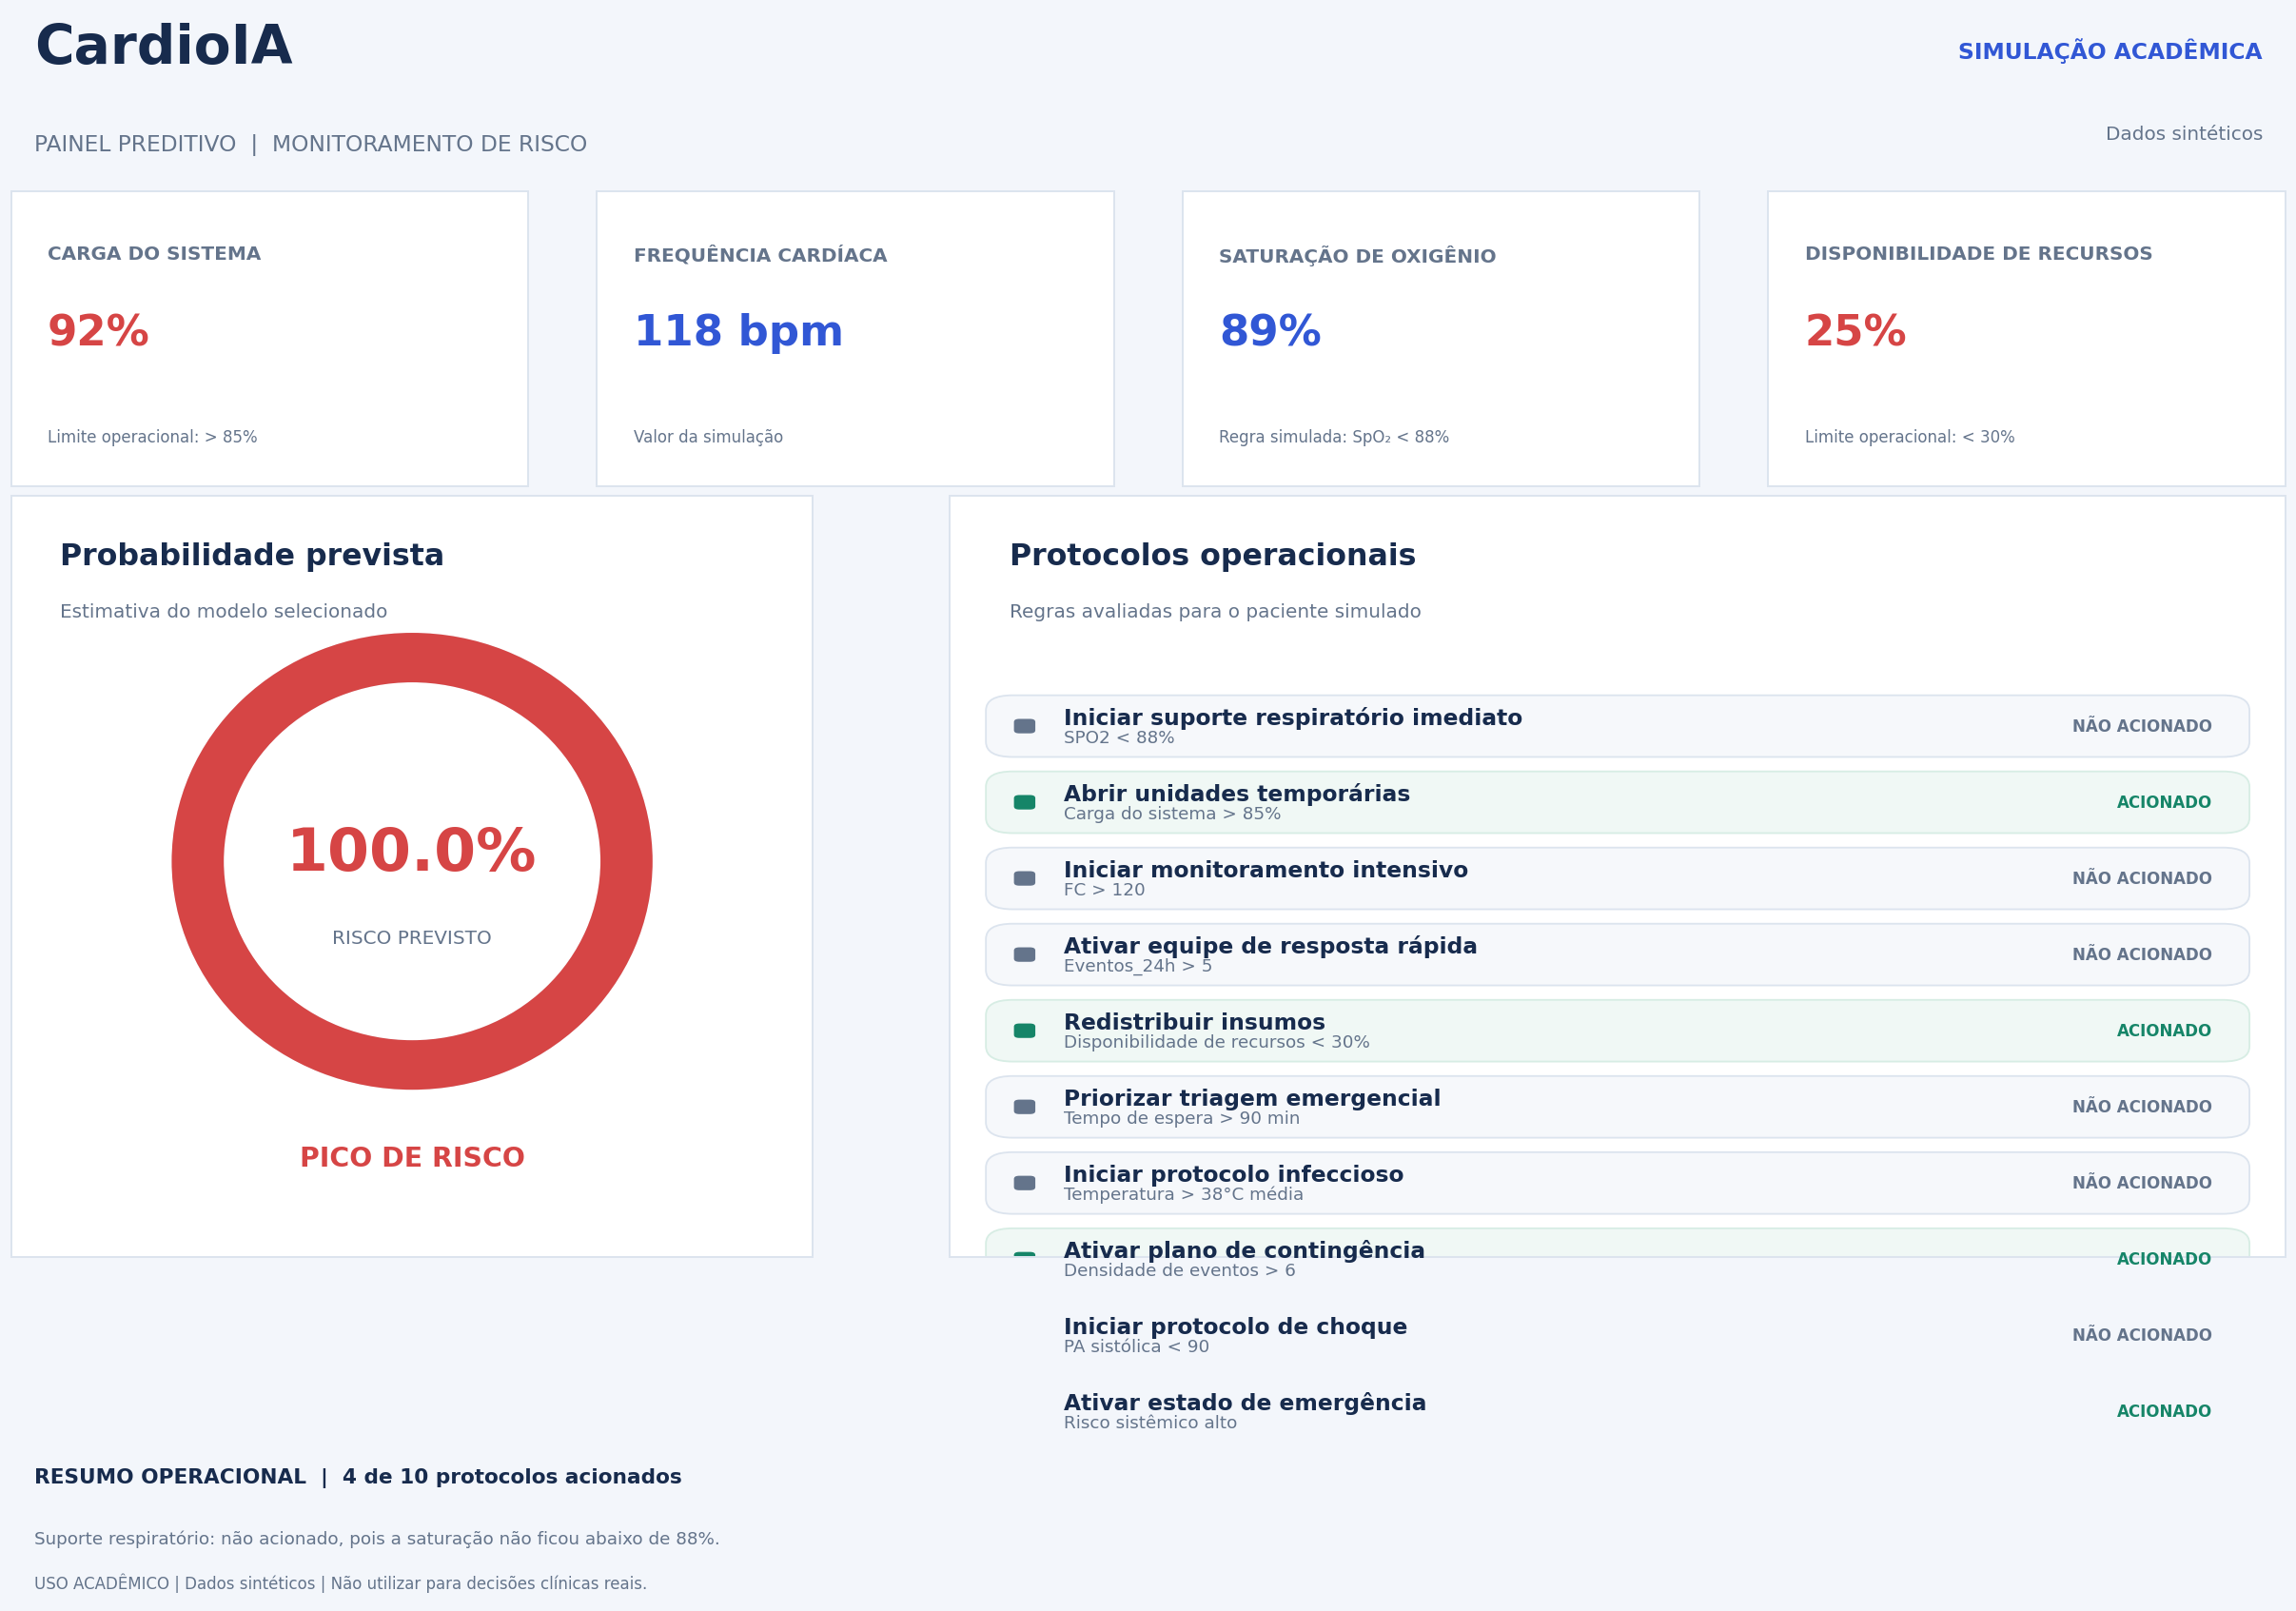

In [58]:

# ============================================================
# CARDIOIA | DASHBOARD PREDITIVO DE RISCO
# Layout ampliado para Google Colab
# ============================================================

# 1. DADOS
paciente = novo_caso.iloc[0]
probabilidade = float(np.clip(probabilidade_arvore, 0, 1))
risco_percentual = probabilidade * 100

classificacao = (
    "PICO DE RISCO" if classe_arvore == 1
    else "SEM PICO DE RISCO"
)

# 2. CORES
FUNDO = "#F3F6FB"
BRANCO = "#FFFFFF"
TEXTO = "#172B4D"
CINZA = "#64748B"
AZUL = "#3157D5"
VERMELHO = "#D64545"
VERDE = "#168568"
BORDA = "#DCE4EE"

cor_risco = VERMELHO if classe_arvore == 1 else VERDE

# Ajustes de exibição do Matplotlib
plt.rcParams.update({
    "figure.dpi": 120,
    "savefig.dpi": 150,
    "font.family": "DejaVu Sans"
})

# 3. FUNÇÕES AUXILIARES
def painel(ax, cor=BRANCO):
    ax.set_facecolor(cor)
    for lado in ax.spines.values():
        lado.set_visible(True)
        lado.set_color(BORDA)
        lado.set_linewidth(1.2)
    ax.set_xticks([])
    ax.set_yticks([])


def cartao_kpi(ax, titulo, valor, detalhe, cor=AZUL):
    ax.set_facecolor(BRANCO)
    for lado in ax.spines.values():
        lado.set_visible(True)
        lado.set_color(BORDA)
        lado.set_linewidth(1.2)

    ax.set_xticks([])
    ax.set_yticks([])
    ax.set_xlim(0, 1)
    ax.set_ylim(0, 1)

    ax.text(
        0.07, 0.82, titulo,
        transform=ax.transAxes,
        fontsize=12, color=CINZA,
        fontweight="bold", va="top",
        wrap=True
    )

    ax.text(
        0.07, 0.52, valor,
        transform=ax.transAxes,
        fontsize=27, color=cor,
        fontweight="bold", va="center"
    )

    ax.text(
        0.07, 0.14, detalhe,
        transform=ax.transAxes,
        fontsize=10, color=CINZA,
        va="bottom", wrap=True
    )


# 4. FIGURA E ORGANIZAÇÃO PRINCIPAL
# O layout usa linhas grandes em vez de posicionamentos manuais.
fig = plt.figure(
    figsize=(20, 14),
    facecolor=FUNDO,
    layout="constrained"
)

gs = fig.add_gridspec(
    4, 1,
    height_ratios=[0.9, 1.6, 5.0, 0.8]
)

# ============================================================
# 5. CABEÇALHO
# ============================================================
ax_titulo = fig.add_subplot(gs[0])
ax_titulo.axis("off")

ax_titulo.text(
    0.01, 0.78, "CardioIA",
    transform=ax_titulo.transAxes,
    fontsize=34, fontweight="bold",
    color=TEXTO, va="center"
)

ax_titulo.text(
    0.01, 0.22,
    "PAINEL PREDITIVO  |  MONITORAMENTO DE RISCO",
    transform=ax_titulo.transAxes,
    fontsize=14, color=CINZA, va="center"
)

ax_titulo.text(
    0.99, 0.72, "SIMULAÇÃO ACADÊMICA",
    transform=ax_titulo.transAxes,
    fontsize=14, color=AZUL,
    fontweight="bold", ha="right"
)

ax_titulo.text(
    0.99, 0.25, "Dados sintéticos",
    transform=ax_titulo.transAxes,
    fontsize=12, color=CINZA,
    ha="right"
)

# ============================================================
# 6. INDICADORES EM QUATRO CARTÕES GRANDES
# ============================================================
gs_kpis = gs[1].subgridspec(1, 4, wspace=0.12)

indicadores = [
    (
        "CARGA DO SISTEMA",
        f'{paciente["carga_sistema"]:.0f}%',
        "Limite operacional: > 85%",
        VERMELHO if paciente["carga_sistema"] > 85 else AZUL
    ),
    (
        "FREQUÊNCIA CARDÍACA",
        f'{paciente["fc_media"]:.0f} bpm',
        "Valor da simulação",
        AZUL
    ),
    (
        "SATURAÇÃO DE OXIGÊNIO",
        f'{paciente["spo2_media"]:.0f}%',
        "Regra simulada: SpO₂ < 88%",
        AZUL
    ),
    (
        "DISPONIBILIDADE DE RECURSOS",
        f'{paciente["disponibilidade_recursos"]:.0f}%',
        "Limite operacional: < 30%",
        VERMELHO
        if paciente["disponibilidade_recursos"] < 30
        else AZUL
    )
]

for i, (titulo, valor, detalhe, cor) in enumerate(indicadores):
    ax = fig.add_subplot(gs_kpis[0, i])
    cartao_kpi(ax, titulo, valor, detalhe, cor)

# ============================================================
# 7. ÁREA PRINCIPAL: RISCO + PROTOCOLOS
# ============================================================
gs_conteudo = gs[2].subgridspec(
    1, 2,
    width_ratios=[0.9, 1.5],
    wspace=0.12
)

# ------------------------------------------------------------
# 7A. PROBABILIDADE DE RISCO
# ------------------------------------------------------------
ax_risco = fig.add_subplot(gs_conteudo[0, 0])
painel(ax_risco)
ax_risco.set_xlim(0, 1)
ax_risco.set_ylim(0, 1)

ax_risco.text(
    0.06, 0.94, "Probabilidade prevista",
    transform=ax_risco.transAxes,
    fontsize=19, fontweight="bold",
    color=TEXTO, va="top"
)

ax_risco.text(
    0.06, 0.86, "Estimativa do modelo selecionado",
    transform=ax_risco.transAxes,
    fontsize=12, color=CINZA, va="top"
)

# Anel proporcional à probabilidade
centro = (0.5, 0.52)
raio = 0.30
espessura = 0.065

ax_risco.add_patch(
    Wedge(
        centro, raio, 0, 360,
        width=espessura,
        facecolor="#E8EDF5",
        edgecolor="none"
    )
)

if probabilidade > 0:
    ax_risco.add_patch(
        Wedge(
            centro, raio,
            90, 90 - 360 * probabilidade,
            width=espessura,
            facecolor=cor_risco,
            edgecolor="none"
        )
    )

ax_risco.text(
    0.5, 0.53, f"{risco_percentual:.1f}%",
    transform=ax_risco.transAxes,
    ha="center", va="center",
    fontsize=38, fontweight="bold",
    color=cor_risco
)

ax_risco.text(
    0.5, 0.42, "RISCO PREVISTO",
    transform=ax_risco.transAxes,
    ha="center", va="center",
    fontsize=12, color=CINZA
)

ax_risco.text(
    0.5, 0.13, classificacao,
    transform=ax_risco.transAxes,
    ha="center", va="center",
    fontsize=17, fontweight="bold",
    color=cor_risco
)

# ------------------------------------------------------------
# 7B. PROTOCOLOS OPERACIONAIS
# ------------------------------------------------------------
ax_protocolos = fig.add_subplot(gs_conteudo[0, 1])
painel(ax_protocolos)
ax_protocolos.set_xlim(0, 1)
ax_protocolos.set_ylim(0, 1)

ax_protocolos.text(
    0.045, 0.94, "Protocolos operacionais",
    transform=ax_protocolos.transAxes,
    fontsize=19, fontweight="bold",
    color=TEXTO, va="top"
)

ax_protocolos.text(
    0.045, 0.86, "Regras avaliadas para o paciente simulado",
    transform=ax_protocolos.transAxes,
    fontsize=12, color=CINZA, va="top"
)

quantidade = len(protocolos)

if quantidade > 0:
    altura = min(0.19, 0.65 / quantidade)
    intervalo = 0.035
    inicio = 0.73 - altura

    for i, protocolo in enumerate(protocolos):
        y = inicio - i * (altura + intervalo)
        acionado = bool(protocolo["Acionado"])

        cor_status = VERDE if acionado else CINZA
        status = "ACIONADO" if acionado else "NÃO ACIONADO"

        ax_protocolos.add_patch(
            FancyBboxPatch(
                (0.035, y), 0.93, altura,
                boxstyle="round,pad=0.008,rounding_size=0.02",
                transform=ax_protocolos.transAxes,
                facecolor="#F0F8F5" if acionado else "#F6F8FB",
                edgecolor="#D7EDE4" if acionado else BORDA,
                linewidth=1.1
            )
        )

        ax_protocolos.add_patch(
            FancyBboxPatch(
                (0.05, y + 0.025), 0.012,
                altura - 0.05,
                boxstyle="round,pad=0.002,rounding_size=0.004",
                transform=ax_protocolos.transAxes,
                facecolor=cor_status,
                edgecolor="none"
            )
        )

        ax_protocolos.text(
            0.085, y + altura * 0.67,
            protocolo["Protocolo"],
            transform=ax_protocolos.transAxes,
            fontsize=14, fontweight="bold",
            color=TEXTO, va="center"
        )

        ax_protocolos.text(
            0.085, y + altura * 0.28,
            protocolo["Condição"],
            transform=ax_protocolos.transAxes,
            fontsize=11, color=CINZA,
            va="center"
        )

        ax_protocolos.text(
            0.945, y + altura * 0.50,
            status,
            transform=ax_protocolos.transAxes,
            fontsize=10, fontweight="bold",
            color=cor_status,
            ha="right", va="center"
        )
else:
    ax_protocolos.text(
        0.5, 0.5, "Nenhum protocolo cadastrado.",
        transform=ax_protocolos.transAxes,
        fontsize=14, color=CINZA,
        ha="center", va="center"
    )

# ============================================================
# 8. RESUMO E AVISO
# ============================================================
ax_rodape = fig.add_subplot(gs[3])
ax_rodape.axis("off")

acionados = sum(bool(p["Acionado"]) for p in protocolos)

ax_rodape.text(
    0.01, 0.80,
    f"RESUMO OPERACIONAL  |  {acionados} de {len(protocolos)} protocolos acionados",
    transform=ax_rodape.transAxes,
    fontsize=13, fontweight="bold",
    color=TEXTO, va="center"
)

if paciente["spo2_media"] < 88:
    resumo = "Suporte respiratório: acionado pela regra simulada de saturação."
else:
    resumo = (
        "Suporte respiratório: não acionado, pois a saturação "
        "não ficou abaixo de 88%."
    )

ax_rodape.text(
    0.01, 0.40, resumo,
    transform=ax_rodape.transAxes,
    fontsize=11, color=CINZA, va="center"
)

ax_rodape.text(
    0.01, 0.05,
    "USO ACADÊMICO | Dados sintéticos | Não utilizar para decisões clínicas reais.",
    transform=ax_rodape.transAxes,
    fontsize=10, color=CINZA, va="bottom"
)

# 9. EXIBIÇÃO
plt.show()


## 10. Salvamento do modelo preditivo

Nesta etapa, vamos salvar a Árvore de Decisão treinada em um arquivo `.pkl`. Isso permite reutilizar o modelo sem precisar treiná-lo novamente, facilitando sua integração futura com o agente de análise de risco.

In [59]:
# Salva o modelo treinado
joblib.dump(modelo_arvore, "cardioia_modelo_risco.pkl")

print("Modelo preditivo salvo com sucesso!")

Modelo preditivo salvo com sucesso!


## 11. Validação do modelo salvo

Nesta etapa, vamos carregar o modelo salvo em arquivo e realizar uma nova previsão com o paciente simulado. O objetivo é verificar se o modelo pode ser reutilizado corretamente, preparando sua integração futura com o agente de análise de risco.

In [60]:
# Verifica se o arquivo existe
arquivo_modelo = "cardioia_modelo_risco.pkl"

if os.path.exists(arquivo_modelo):
    print("Arquivo do modelo encontrado!")

    # Carrega o modelo salvo
    modelo_carregado = joblib.load(arquivo_modelo)

    # Realiza uma nova previsão
    classe_teste = modelo_carregado.predict(novo_caso)[0]

    indice_positivo = list(modelo_carregado.classes_).index(1)
    probabilidade_teste = modelo_carregado.predict_proba(
        novo_caso
    )[0, indice_positivo]

    print(f"\nProbabilidade prevista: {probabilidade_teste:.2%}")
    print(
        "Classificação:",
        "Pico de risco" if classe_teste == 1 else "Sem pico de risco"
    )

else:
    print("Arquivo não encontrado. Execute novamente a etapa de salvamento.")

Arquivo do modelo encontrado!

Probabilidade prevista: 100.00%
Classificação: Pico de risco


## 12. Exportação do modelo treinado

Vamos baixar o arquivo do modelo para armazená-lo junto aos materiais do projeto CardioIA. Esse arquivo poderá ser reutilizado posteriormente, desde que o ambiente tenha as dependências necessárias.

In [61]:
files.download("cardioia_modelo_risco.pkl")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 13. Padronização da previsão para integração multiagente

Nesta etapa, vamos reunir a previsão do modelo e os protocolos acionados em um único dicionário Python. Essa estrutura poderá ser utilizada pelo futuro agente de análise de risco e compartilhada com os demais agentes do sistema.

In [62]:
# Utiliza o modelo carregado na etapa anterior

paciente = novo_caso.iloc[0]

classe = int(modelo_carregado.predict(novo_caso)[0])

indice_positivo = list(modelo_carregado.classes_).index(1)

probabilidade = float(
    modelo_carregado.predict_proba(novo_caso)[0, indice_positivo]
)

# Avalia os protocolos operacionais simulados
protocolos_acionados = []

if paciente["carga_sistema"] > 85:
    protocolos_acionados.append({
        "protocolo": "Abrir unidades temporárias",
        "motivo": "Carga do sistema superior a 85%"
    })

if paciente["spo2_media"] < 88:
    protocolos_acionados.append({
        "protocolo": "Iniciar suporte respiratório",
        "motivo": "Saturação inferior a 88%"
    })

if paciente["disponibilidade_recursos"] < 30:
    protocolos_acionados.append({
        "protocolo": "Redistribuir insumos",
        "motivo": "Disponibilidade de recursos inferior a 30%"
    })

# Saída padronizada para integração
resultado_risco = {
    "probabilidade": round(probabilidade, 4),
    "classificacao": (
        "Pico de risco" if classe == 1 else "Sem pico de risco"
    ),
    "protocolos_acionados": protocolos_acionados,
    "origem_dados": "simulacao_sintetica"
}

print("RESULTADO PADRONIZADO PARA OS AGENTES\n")
print(resultado_risco)

RESULTADO PADRONIZADO PARA OS AGENTES

{'probabilidade': 1.0, 'classificacao': 'Pico de risco', 'protocolos_acionados': [{'protocolo': 'Abrir unidades temporárias', 'motivo': 'Carga do sistema superior a 85%'}, {'protocolo': 'Redistribuir insumos', 'motivo': 'Disponibilidade de recursos inferior a 30%'}], 'origem_dados': 'simulacao_sintetica'}


## 14. Padronização da previsão para integração multiagente

Nesta etapa, a saída do modelo preditivo é organizada em uma estrutura padronizada contendo as principais informações necessárias para as próximas etapas do sistema.

O resultado reúne:

- probabilidade estimada de pico de risco;
- classificação do risco;
- protocolos operacionais identificados;
- informações do caso analisado.

Essa estrutura será utilizada como ponto de integração com o sistema multiagente desenvolvido na segunda parte do projeto.

In [63]:
assert 0 <= resultado_risco["probabilidade"] <= 1
assert resultado_risco["classificacao"] in [
    "Pico de risco",
    "Sem pico de risco"
]
assert isinstance(resultado_risco["protocolos_acionados"], list)

print("Validação concluída com sucesso!")
print("Campos disponíveis:", list(resultado_risco.keys()))

Validação concluída com sucesso!
Campos disponíveis: ['probabilidade', 'classificacao', 'protocolos_acionados', 'origem_dados']


## 15. Validação do resultado preditivo

Antes de disponibilizar o resultado para os agentes, são realizadas verificações básicas para garantir que a estrutura produzida pelo modelo esteja consistente.

São verificadas a validade da probabilidade, a existência de uma classificação válida e a presença das informações necessárias para a próxima etapa do sistema.

# 🤖 Parte 2
## 16. Preparação para o sistema multiagente

A primeira etapa do projeto é concluída com a preparação dos dados necessários para integração ao sistema multiagente.

O modelo preditivo já é capaz de:

1. receber um caso hospitalar simulado;
2. estimar a probabilidade de pico de risco;
3. classificar o nível de risco;
4. identificar protocolos operacionais aplicáveis;
5. organizar essas informações em uma estrutura padronizada.

Na segunda parte do projeto, esses resultados serão utilizados por agentes especializados, responsáveis por interpretar a previsão, consultar informações e organizar as possíveis respostas operacionais.

> **A implementação da arquitetura multiagente será realizada na Parte 2 do projeto.**